In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from sklearn.preprocessing import StandardScaler
import copy
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Dataset

Easwaramoorthy, S. (2020). Seoul Bike Sharing Demand [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F62R.

Sathishkumar, V. E., Park, J., & Cho, Y. (2020). Using data mining techniques for bike sharing demand prediction in metropolitan city. Computer Communications, 153, 353–366. https://doi.org/10.1016/j.comcom.2020.02.007

Sathishkumar, V. E., & Cho, Y. (2020). A rule-based model for Seoul Bike sharing demand prediction using weather data. European Journal of Remote Sensing, 53(sup1), 166–183. https://doi.org/10.1080/22797254.2020.1725789 

Source: [Seoul Bike Sharing Demand](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

In [2]:
dataset_cols = ["bike_count", "hour", "temp", "humidity", "wind", "visibility", "dew_pt_temp", "radiation", "rain", "snow", "functional"]
df = pd.read_csv("./seoul+bike+sharing+demand/SeoulBikeData.csv").drop(["Date", "Holiday", "Seasons"], axis=1)

In [3]:
df.columns = dataset_cols
df["functional"] = (df["functional"] == "Yes").astype(int)
df = df[df["hour"] == 12]
df = df.drop(["hour"], axis=1)

In [4]:
df.head()

,bike_count,temp,humidity,wind,visibility,dew_pt_temp,radiation,rain,snow,functional
12,449,1.7,23,1.4,2000,-17.2,1.11,0.0,0.0,1
36,479,4.3,41,1.3,1666,-7.8,1.09,0.0,0.0,1
60,333,5.8,85,1.7,349,3.4,0.43,0.0,0.0,1
84,393,-0.3,38,4.8,1823,-12.9,1.11,0.0,0.0,1
108,321,-2.3,25,0.0,1962,-19.7,0.00,0.0,0.0,1


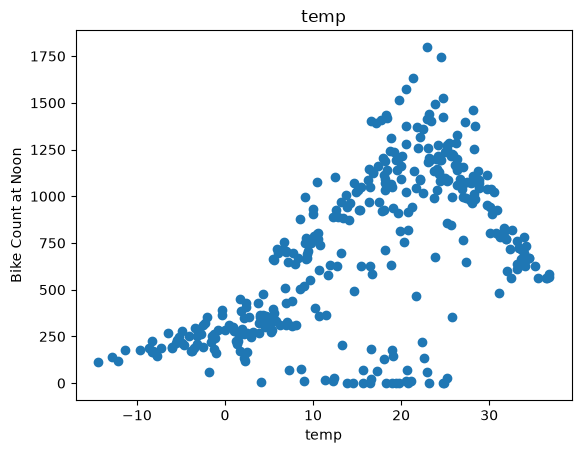

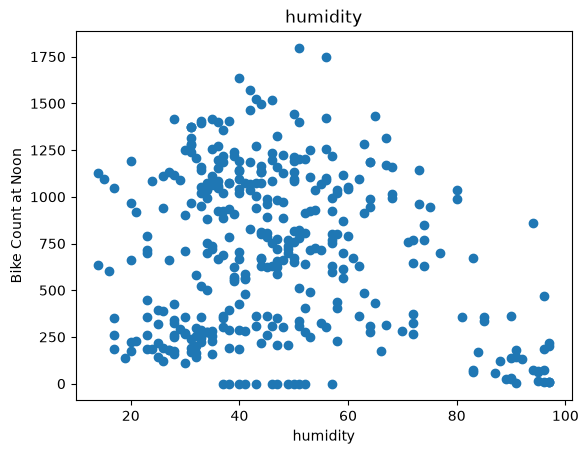

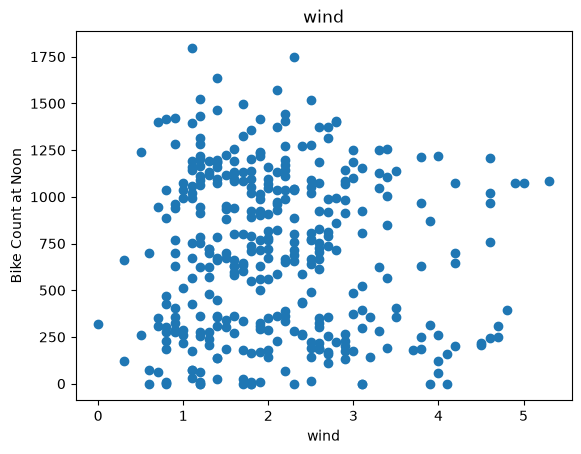

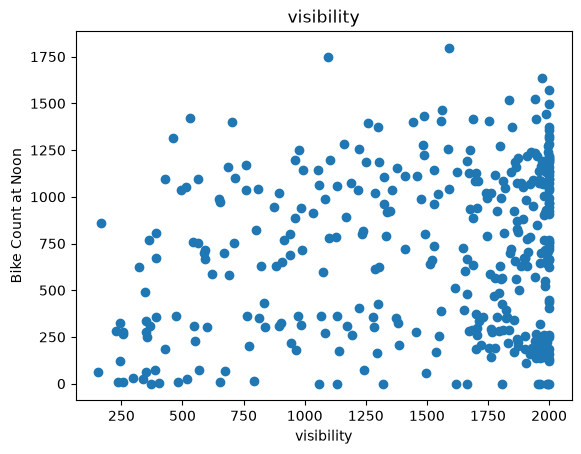

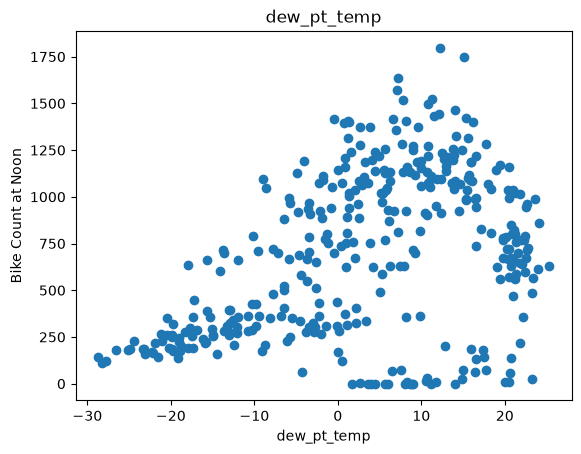

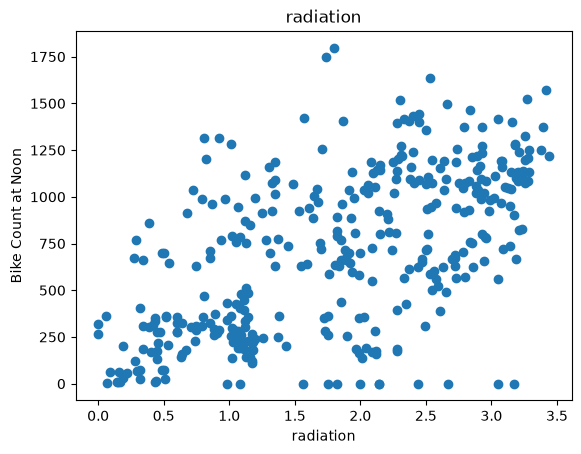

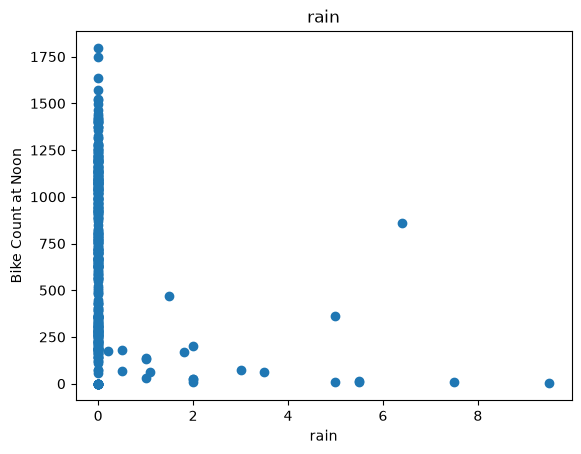

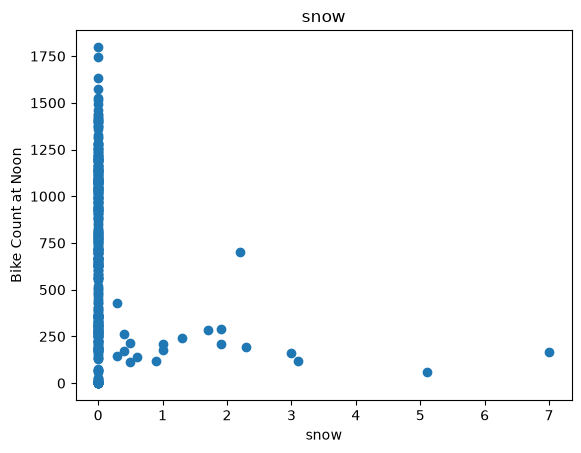

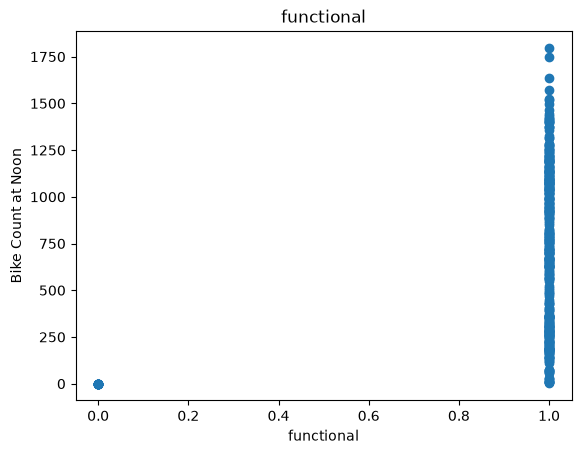

In [5]:
for label in df.columns[1:]:
  plt.scatter(df[label], df["bike_count"])
  plt.title(label)
  plt.ylabel("Bike Count at Noon")
  plt.xlabel(label)
  plt.show()

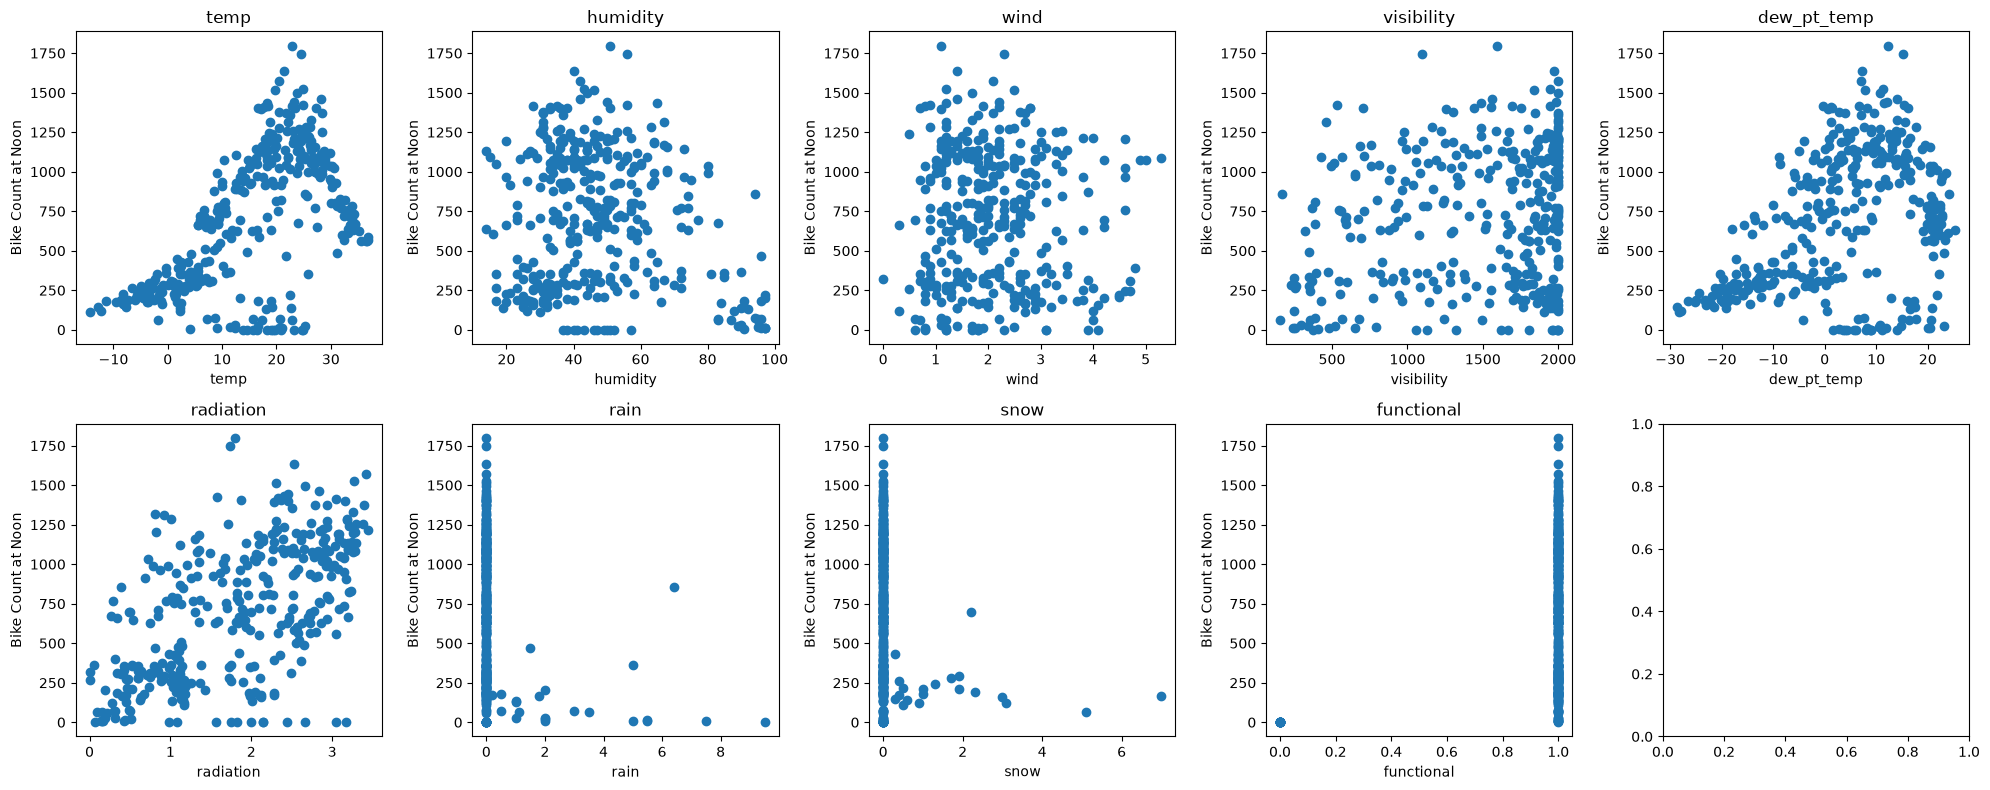

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=False)
axes = axes.flatten()
for i, label in enumerate(df.columns[1:]):
  axes[i].scatter(df[label], df["bike_count"])
  axes[i].set_title(label)
  axes[i].set_ylabel("Bike Count at Noon")
  axes[i].set_xlabel(label)
plt.tight_layout()
plt.show()
  

In [9]:
df = df.drop(["wind", "visibility", "functional"], axis=1)

In [10]:
df.head()

,bike_count,temp,humidity,dew_pt_temp,radiation,rain,snow
12,449,1.7,23,-17.2,1.11,0.0,0.0
36,479,4.3,41,-7.8,1.09,0.0,0.0
60,333,5.8,85,3.4,0.43,0.0,0.0
84,393,-0.3,38,-12.9,1.11,0.0,0.0
108,321,-2.3,25,-19.7,0.00,0.0,0.0


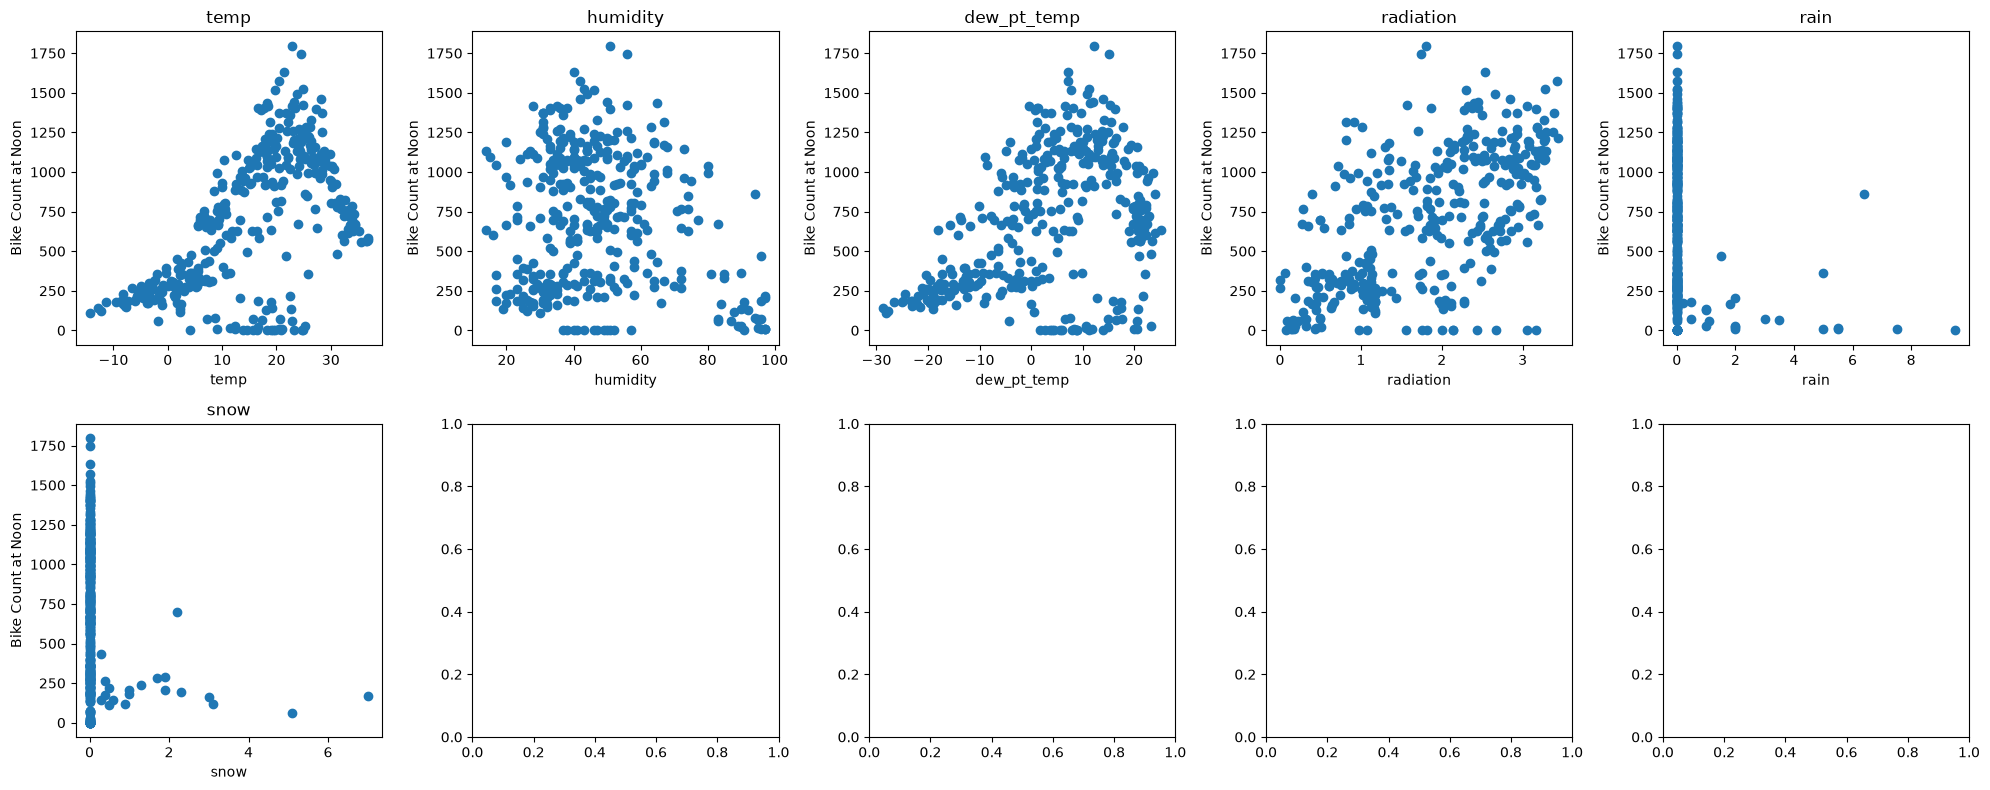

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8), sharex=False)
axes = axes.flatten()
for i, label in enumerate(df.columns[1:]):
  axes[i].scatter(df[label], df["bike_count"])
  axes[i].set_title(label)
  axes[i].set_ylabel("Bike Count at Noon")
  axes[i].set_xlabel(label)
plt.tight_layout()
plt.show()

# Train/valid/test dataset

In [13]:
df_shuffled = df.sample(frac=1, random_state=42).reset_index(drop=True)
n = len(df_shuffled)
train = df_shuffled.iloc[:int(0.6*n)]
valid = df_shuffled.iloc[int(0.6*n):int(0.8*n)]
test = df_shuffled.iloc[int(0.8*n):]

In [14]:
# Validate data type
print(type(train), type(valid), type(test))

<class 'pandas.DataFrame'> <class 'pandas.DataFrame'> <class 'pandas.DataFrame'>


In [15]:
# Check sum of splitted data sets
print(len(df_shuffled), len(train), len(valid), len(test))
print(len(train) + len(valid) + len(test))

365 219 73 73
365


In [18]:
# Check overlap
# Three times empty set -> disjunkt
print(set(train.index) & set(valid.index))
print(set(valid.index) & set(test.index))
print(set(train.index) & set(test.index))

set()
set()
set()


In [19]:
# Percentage shares
print(len(train)/n, len(valid)/n, len(test)/n)

0.6 0.2 0.2


In [ ]:
# 2:44:58